In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, IIDTrainer, free_gpu

## 1. Load & Build Persona Datasets

In [2]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
N_ISSP_PER_YEAR = 4
N_TWIN_FAMILIES = 40
MAX_VALID_RESP_PER_QID = 100
SIM_THRESHOLD = 0.95

issp_df = load_issp_df()
twin_df = load_twin2k_df()
all_df = pd.concat([issp_df, twin_df], ignore_index=True)
q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()

print(
    f"ISSP    : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} questions\n"
    f"Twin-2K : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} questions\n"
    f"Total   : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} questions"
)

ISSP    :    767,484 rows |  616 questions
Twin-2K :  1,127,649 rows |  974 questions
Total   :  1,895,133 rows | 1590 questions


In [3]:
import random

rng = random.Random(VALID_SEED)

valid_by_group = {}
candidate_queues = {}
issp_summary_rows = []

for yr, grp in sorted(issp_df.groupby(issp_df["qid"].str.split(":").str[0])):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[yr] = shuffled[:N_ISSP_PER_YEAR]
    candidate_queues[yr] = shuffled[N_ISSP_PER_YEAR:]
    issp_summary_rows.append({
        "year": yr,
        "total_qids": len(qids),
        "initial_candidates": ", ".join(valid_by_group[yr]),
        "backups": len(candidate_queues[yr]),
    })

display(pd.DataFrame(issp_summary_rows))

,year,total_qids,initial_candidates,backups
0,2015,82,"2015:v54, 2015:v58, 2015:v13, 2015:v4",78
1,2016,60,"2016:v28, 2016:v42, 2016:v23, 2016:v26",56
2,2017,60,"2017:v57, 2017:v42, 2017:v46, 2017:v40",56
3,2018,62,"2018:v29, 2018:v42, 2018:v24, 2018:v16",58
4,2019,49,"2019:v57, 2019:v61, 2019:v2, 2019:v28",45
5,2020,55,"2020:v38, 2020:v33, 2020:v47, 2020:v14",51
6,2021,58,"2021:v25, 2021:v19, 2021:v18, 2021:v43",54
7,2022,55,"2022:v47, 2022:v45, 2022:v28, 2022:v40",51
8,2023,60,"2023:v1, 2023:v29, 2023:v52, 2023:v54",56
9,2024,75,"2024:v44, 2024:v68, 2024:v75, 2024:v39",71


In [4]:
import random

rng = random.Random(VALID_SEED)

twin_by_family = {}
for qid in sorted(twin_df["qid"].unique()):
    fam = qid.split("_")[0]
    twin_by_family.setdefault(fam, []).append(qid)

shuffled_families = rng.sample(sorted(twin_by_family), len(twin_by_family))
twin_pool = [rng.choice(twin_by_family[fam]) for fam in shuffled_families]
valid_by_group["twin2k"] = twin_pool[:N_TWIN_FAMILIES]
candidate_queues["twin2k"] = twin_pool[N_TWIN_FAMILIES:]

print(
    f"Twin-2K families   : {len(twin_by_family)} total\n"
    f"Initial candidates : {len(valid_by_group['twin2k'])} ({len(candidate_queues['twin2k'])} backup families)\n"
    f"Sampled Twin-2K    : {valid_by_group['twin2k'][:10]} ..."
)

Twin-2K families   : 119 total
Initial candidates : 40 (79 backup families)
Sampled Twin-2K    : ['twin2k:QID75', 'twin2k:QID237_8', 'twin2k:QID63', 'twin2k:QID80', 'twin2k:QID245_4', 'twin2k:QID151', 'twin2k:QID194', 'twin2k:QID273', 'twin2k:QID27_12', 'twin2k:QID239_2'] ...


In [5]:
import numpy as np
from rapidfuzz import fuzz, process

def find_train_matches(valid_qids, q_text_map, threshold=SIM_THRESHOLD):
    valid_set = set(valid_qids)
    train_qids = [q for q in q_text_map if q not in valid_set]
    scores = process.cdist(
        [q_text_map[q] for q in valid_qids],
        [q_text_map[q] for q in train_qids],
        scorer=fuzz.ratio,
        dtype=np.float64,
        workers=-1,
    ) / 100.0
    best = scores.argmax(axis=1)
    return {
        vq: (train_qids[j], float(scores[i, j]))
        for i, (vq, j) in enumerate(zip(valid_qids, best))
        if scores[i, j] >= threshold
    }

round_idx = 0
while True:
    round_idx += 1
    current_valid = [q for grp in sorted(valid_by_group) for q in valid_by_group[grp]]
    matches = find_train_matches(current_valid, q_text_map, threshold=SIM_THRESHOLD)
    if not matches:
        print(f"\nRound {round_idx}: 0 matches >= {SIM_THRESHOLD}. All {len(current_valid)} valid questions passed!")
        break

    print(f"\n=== Round {round_idx}: {len(matches)} valid question(s) matched train (>= {SIM_THRESHOLD}) ===")
    for grp in sorted(valid_by_group):
        for i, vq in enumerate(valid_by_group[grp]):
            if vq in matches:
                tq, sim = matches[vq]
                replacement = candidate_queues[grp].pop(0)
                print(
                    f"[{grp}] {vq} -> replaced with {replacement} (matched {tq}, sim={sim:.3f})\n"
                    f"  Valid: {q_text_map[vq]}\n"
                    f"  Train: {q_text_map[tq]}"
                )
                valid_by_group[grp][i] = replacement

VALID_ISSP_QIDS = [q for grp in sorted(valid_by_group) if grp != "twin2k" for q in valid_by_group[grp]]
VALID_TWIN_QIDS = list(valid_by_group["twin2k"])
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS


=== Round 1: 21 valid question(s) matched train (>= 0.95) ===
[2016] 2016:v42 -> replaced with 2016:v2 (matched 2016:v41, sim=0.975)
  Valid: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in other countries without their knowledge
  Train: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in the United States without their knowledge
[2016] 2016:v26 -> replaced with 2016:v20 (matched 2016:v24, sim=0.969)
  Valid: On the whole, do you think it should or should not be the government's responsibility to ... ... provide a decent standard 

In [6]:
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_df = all_df[~all_df["qid"].isin(VALID_QIDS)].reset_index(drop=True)
valid_full_df = all_df[all_df["qid"].isin(VALID_QIDS)]
valid_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)

if not set(train_df["qid"]).isdisjoint(valid_df["qid"]):
    raise AssertionError("Leakage detected between train_df and valid_df qids")

print(
    f"train_df      : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions\n"
    f"valid_full_df : {len(valid_full_df):>10,} rows | {valid_full_df['qid'].nunique():>4} questions (all excluded from train)\n"
    f"valid_df (sub): {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} questions (<= {MAX_VALID_RESP_PER_QID} resp/question)"
)

train_df      :  1,764,410 rows | 1510 questions
valid_full_df :    130,723 rows |   80 questions (all excluded from train)
valid_df (sub):      8,000 rows |   80 questions (<= 100 resp/question)


### Check max valid/train question similarity

In [7]:
valid_set = sorted(valid_df["qid"].unique())
train_qids = sorted(train_df["qid"].unique())
scores = process.cdist(
    [q_text_map[q] for q in valid_set],
    [q_text_map[q] for q in train_qids],
    scorer=fuzz.ratio,
    dtype=np.float64,
    workers=-1,
) / 100.0
best = scores.argmax(axis=1)
matches = {vq: (train_qids[j], float(scores[i, j])) for i, (vq, j) in enumerate(zip(valid_set, best))}
max_sim = max(sim for _, sim in matches.values())

print(f"Max similarity across all {len(valid_set)} valid questions vs {len(train_qids)} train questions: {max_sim:.4f}\n")

top10 = sorted(matches.items(), key=lambda kv: kv[1][1], reverse=True)[:10]
for rank, (vq, (tq, sim)) in enumerate(top10, start=1):
    print(
        f"{rank:2d}. sim={sim:.3f} | valid={vq} vs train={tq}\n"
        f"    Valid: {q_text_map[vq]}\n"
        f"    Train: {q_text_map[tq]}"
    )

Max similarity across all 80 valid questions vs 1510 train questions: 0.9494

 1. sim=0.949 | valid=twin2k:QID83 vs train=twin2k:QID78
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to VACUOUS
    Train: Antonym: Select the word that is most nearly the opposite in meaning to VERBOSE
 2. sim=0.948 | valid=twin2k:QID76 vs train=twin2k:QID74
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to ALOOF
    Train: Antonym: Select the word that is most nearly the opposite in meaning to SATED
 3. sim=0.948 | valid=2020:v26 vs train=2020:v27
    Valid: How willing would you be to pay much higher prices in order to protect the environment?
    Train: how willing would you be to pay much higher taxes in order to protect the environment?
 4. sim=0.947 | valid=twin2k:QID65 vs train=twin2k:QID69
    Valid: Synonym: Select the word that is most nearly the same in meaning as SOLICIT
    Train: Synonym: Select the word that is most nearly th

### build datasets

In [8]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_diverse80"
)
valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid_diverse80", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train records : {len(train_records):,}\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

Loaded 1,764,410 records from train_records_diverse80_minNone_74398c39.pkl
Loaded 8,000 records from valid_diverse80_records_minNone_0df15406.pkl
Train records : 1,764,410
Eval sets     : valid=8,000 (3,939 states), grummon=33,798 (3,652 states)


In [9]:
train_rec_qids = {r["qid"] for r in train_records}
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon_rec_qids = {r["qid"] for r in grummon_grouped["records"]}
all_qids = set(all_df["qid"].unique())

train_rec_texts = {r["question"].strip() for r in train_records}
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon_rec_texts = {r["question"].strip() for r in grummon_grouped["records"]}

assert len(train_records) == len(train_df), f"{len(train_records)} != {len(train_df)}"
assert len(valid_grouped["records"]) == len(valid_df), f"{len(valid_grouped['records'])} != {len(valid_df)}"
assert train_rec_qids == all_qids - set(VALID_QIDS)
assert valid_rec_qids == set(VALID_QIDS)
assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon_rec_qids), f"Train/Grummon QID overlap: {train_rec_qids & grummon_rec_qids}"
assert valid_rec_qids.isdisjoint(grummon_rec_qids), f"Valid/Grummon QID overlap: {valid_rec_qids & grummon_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between train and grummon!"
assert valid_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between valid and grummon!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid={len(valid_rec_qids):,}, grummon={len(grummon_rec_qids):,} "
    f"(train+valid={len(train_rec_qids | valid_rec_qids):,} / {len(all_qids):,} in all_df)\n"
    f"QID overlaps     : train∩valid={len(train_rec_qids & valid_rec_qids)}, "
    f"train∩grummon={len(train_rec_qids & grummon_rec_qids)}, "
    f"valid∩grummon={len(valid_rec_qids & grummon_rec_qids)}\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon={len(train_rec_texts & grummon_rec_texts)}, "
    f"valid∩grummon={len(valid_rec_texts & grummon_rec_texts)}\n"
    f"All dataset split sanity checks passed!"
)

QID counts       : train=1,510, valid=80, grummon=36 (train+valid=1,590 / 1,590 in all_df)
QID overlaps     : train∩valid=0, train∩grummon=0, valid∩grummon=0
Question overlaps: train∩valid=0, train∩grummon=0, valid∩grummon=0
All dataset split sanity checks passed!


## 2. Configure & Instantiate Trainer


In [ ]:
resume = True
val_every = [50, 200]
save_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-diversevalid-iid",
        weights_dtype="bf16",
        use_bf16=True,
        batch_size=26,
        grad_accum_steps=12,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        batch_size=12,
        grad_accum_steps=26,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = IIDTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    sort_within_step=True,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,iid
run_name,kev-0.8b-resp-issp+twin2k-grouped-diversevalid...
save_dir,runs/kev-0.8b-resp-issp+twin2k-grouped-diverse...
init_from,runs/kev-0.8b-resp-issp+twin2k-grouped-diverse...
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,released adapter
resume,True
seed,0
epochs,1


## Run eval

In [22]:
# Test one full evaluation loop across all eval sets with progress bars:
eval_summaries, eval_extra_dfs = trainer.evaluate(show_progress=True)
for s in trainer.eval_sets:
    name = s["name"]
    st = s["last_stats"]
    print(
        f"{name}: {st['n_batches']} batches ({st['n_views_run']:,} states, {st['n_records']:,} records) "
        f"in {st['total_sec']:.2f}s (gpu={st['gpu_sec']:.2f}s)"
    )
    display(eval_summaries[name].to_frame(name=name))

Evaluating valid_diverse80 (shared-state):   0%|          | 0/32 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/46 [00:00<?, ?batch/s]

valid_diverse80: 32 batches (3,939 states, 8,000 records) in 16.65s (gpu=16.57s)


,valid_diverse80
ce,2.723849
dist_kl,2.723849


grummon: 46 batches (3,652 states, 33,798 records) in 30.42s (gpu=30.21s)


,grummon
ce,2.022351
dist_kl,2.022351
OLS MAPE (%),104.125182
OLS MSE,0.014924
OLS MAE,0.116413
Spearman rho,-0.900000


## Verify fused weights

In [23]:
# Verify model train mode, weights, module attributes, forward loss, and backward gradients are identical pre/post fused eval:
import importlib
import types
import torch
import data.base as _base_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
importlib.reload(_base_mod)
importlib.reload(_trainer_mod)
importlib.reload(_iid_trainer_mod)
from data.base import fused_eval_context, make_view

trainer.model.train()
for _, _m in trainer.model.net.lm.named_modules():
    if "forward" in _m.__dict__ and isinstance(_m.__dict__["forward"], types.MethodType) and _m.__dict__["forward"].__func__ is type(_m).forward:
        del _m.__dict__["forward"]
sample_records = trainer._epoch_groups_for(0)[:8]
prepared = [trainer.model.prepare(make_view(r)) for r in sample_records]

def _sample_loss():
    torch.manual_seed(1234)
    torch.cuda.manual_seed_all(1234)
    with trainer._autocast():
        logits_batch = trainer.model.forward([enc for enc, _ in prepared], shared_prefix=False)
    return torch.stack([
        -(q["target"].to(trainer.device) * torch.log_softmax(z.float(), dim=-1)).sum()
        for (_, targets), record_logits in zip(prepared, logits_batch, strict=True)
        for z, q in zip(record_logits, targets, strict=True)
    ]).mean()

trainer.model.net.zero_grad(set_to_none=True)
pre_loss = _sample_loss()
pre_loss.backward()
pre_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
pre_loss2 = _sample_loss()
pre_loss2.backward()
pre_grads2 = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
baseline_grad_diff = max((pre_grads[n] - pre_grads2[n]).abs().max().item() for n in pre_grads)
del pre_grads2
pre_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
pre_params = {n: (p.dtype, p.requires_grad, p.detach().clone()) for n, p in trainer.model.net.named_parameters()}

s0 = trainer.eval_sets[0]
b_encs = s0["encs"][:4] if s0["encs"] is not None else [trainer.model.prepare(v)[0] for v in s0["packed_views"][:4]]
trainer.model.eval()
eval_dtype = torch.bfloat16 if trainer.eval_bf16 else None
with torch.no_grad(), trainer._eval_autocast(), fused_eval_context(trainer.model, eval_dtype=eval_dtype):
    trainer.model.net.probs_batch(b_encs, [None] * len(b_encs), [False] * len(b_encs))
trainer.model.train()

post_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
assert pre_dict_keys == post_dict_keys, "Module __dict__ keys changed!"
assert trainer.model.net.graphs is None, "CudaGraphs was not released!"
for n, p in trainer.model.net.named_parameters():
    dt, req_grad, t_pre = pre_params[n]
    assert p.dtype == dt and p.requires_grad == req_grad and torch.equal(p, t_pre), f"Param changed: {n}"

post_loss = _sample_loss()
post_loss.backward()
post_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
free_gpu()

loss_diff = (pre_loss - post_loss).abs().item()
max_grad_diff = max((pre_grads[n] - post_grads[n]).abs().max().item() for n in pre_grads)
print(f"Pre/post fused eval check PASSED | training={trainer.model.training} | loss_diff={loss_diff:.3e} | max_grad_diff={max_grad_diff:.3e} (baseline backward atomicAdd noise={baseline_grad_diff:.3e})")

Pre/post fused eval check PASSED | training=True | loss_diff=0.000e+00 | max_grad_diff=1.953e-03 (baseline backward atomicAdd noise=3.418e-03)


## Test speed on train step

In [13]:
import heapq
import math
import random
import time
import traceback
import numpy as np
import pandas as pd
import torch
from data.base import _record_chars

CANDIDATE_BATCH_SIZES = [8, 12, 16, 20, 24, 26, 28, 32]

rec_len = lambda r: len(r["persona"]) + _record_chars(r)
n_records = len(trainer.train_records) if trainer.samples_per_epoch is None else min(trainer.samples_per_epoch, len(trainer.train_records))
shuffled_records = list(trainer.train_records)
random.Random(f"{trainer.seed}:epoch:0").shuffle(shuffled_records)
if trainer.samples_per_epoch is not None:
    shuffled_records = shuffled_records[:trainer.samples_per_epoch]

# Find the longest (worst-case) records across the entire training set
max_bs = max(CANDIDATE_BATCH_SIZES)
worst_records = heapq.nlargest(max_bs, shuffled_records, key=rec_len)
worst_lens = [rec_len(r) for r in worst_records]
sample_lens = [rec_len(r) for r in shuffled_records[:1000]]
print(
    f"Sample 1,000 records chars -> median={int(np.median(sample_lens)):,}, p95={int(np.percentile(sample_lens, 95)):,}, max={max(sample_lens):,}\n"
    f"Top-{max_bs} worst-case records chars -> max={worst_lens[0]:,}, min={worst_lens[-1]:,}, mean={int(np.mean(worst_lens)):,}"
)

orig_batch_size = trainer.batch_size
orig_trainable = {n: p.detach().clone() for n, p in trainer.model.net.named_parameters() if p.requires_grad}
bs_rows = []

try:
    if trainer.gradient_checkpointing:
        trainer.model.enable_checkpointing()
    trainer.model.train()

    for bs in CANDIDATE_BATCH_SIZES:
        trainer.batch_size = bs
        q_per_step = bs * trainer.grad_accum_steps
        steps_per_epoch = math.ceil(n_records / q_per_step)
        total_steps = steps_per_epoch * trainer.epochs

        # Replace the final microbatch with the bs longest records in the dataset
        worst_mb = list(worst_records[:bs])
        macro_batch = list(shuffled_records[: q_per_step - bs]) + worst_mb
        if trainer.sort_within_step:
            macro_batch.sort(key=rec_len)

        for n, p in trainer.model.net.named_parameters():
            if p.requires_grad:
                p.data.copy_(orig_trainable[n])
                p.grad = None

        opt = sched = None
        try:
            opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=trainer.lr, weight_decay=trainer.weight_decay)
            sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=trainer.lr, total_steps=total_steps, pct_start=trainer.pct_start)

            # Warmup on the worst-case microbatch first (materializes AdamW state tensors and fails fast on OOM)
            trainer.train_one_step(worst_mb, optimizer=opt, scheduler=sched, step=0, total_steps=total_steps, rng=random.Random(0))
            for n, p in trainer.model.net.named_parameters():
                if p.requires_grad:
                    p.data.copy_(orig_trainable[n])
                    p.grad = None
            for st in opt.state.values():
                for v in st.values():
                    if torch.is_tensor(v) and v.is_floating_point():
                        v.zero_()

            free_gpu()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            step_kls = trainer.train_one_step(macro_batch, optimizer=opt, scheduler=sched, step=0, total_steps=total_steps, rng=random.Random(0))
            torch.cuda.synchronize()
            dt = time.perf_counter() - t0
            peak_gib = torch.cuda.max_memory_allocated() / (1024 ** 3)

            bs_rows.append({
                "batch_size": bs,
                "grad_accum": trainer.grad_accum_steps,
                "questions_per_step": q_per_step,
                "steps_per_epoch": steps_per_epoch,
                "worst_mb_chars": sum(rec_len(r) for r in worst_mb),
                "step_sec": round(dt, 3),
                "rec_per_sec": round(len(macro_batch) / dt, 1),
                "est_epoch_min": round(dt * steps_per_epoch / 60, 1),
                "est_epoch_hr": round(dt * steps_per_epoch / 3600, 2),
                "peak_vram_gib": round(peak_gib, 2),
                "mean_train_kl": round(float(np.mean(step_kls)), 6),
            })
            del opt, sched
        except torch.cuda.OutOfMemoryError as e:
            traceback.clear_frames(e.__traceback__)
            trainer.model.net.zero_grad(set_to_none=True)
            del opt, sched
            free_gpu()
            bs_rows.append({
                "batch_size": bs,
                "grad_accum": trainer.grad_accum_steps,
                "questions_per_step": q_per_step,
                "steps_per_epoch": steps_per_epoch,
                "worst_mb_chars": sum(rec_len(r) for r in worst_mb),
                "step_sec": None,
                "rec_per_sec": None,
                "est_epoch_min": None,
                "est_epoch_hr": None,
                "peak_vram_gib": "OOM",
                "mean_train_kl": None,
            })
            break
finally:
    trainer.batch_size = orig_batch_size
    for n, p in trainer.model.net.named_parameters():
        if p.requires_grad:
            p.data.copy_(orig_trainable[n])
            p.grad = None
    free_gpu()

df_bs_bench = pd.DataFrame(bs_rows)
display(df_bs_bench)

Sample 1,000 records chars -> median=820, p95=1,137, max=2,864
Top-32 worst-case records chars -> max=2,887, min=2,876, mean=2,879


[W1109 14:38:39.926977704 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 56623104 bytes (free: 72024064, total: 33743044608).
[W1109 14:38:40.262279452 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 150994944 bytes (free: 102367232, total: 33743044608).
[W1109 14:38:40.362033774 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 75497472 bytes (free: 102694912, total: 33743044608).
[W1109 14:38:40.398416029 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 75497472 bytes (free: 116326400, total: 33743044608).
[W1109 14:38:40.398563170 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 75497472 bytes (free: 116326400, total: 33743044608).


,batch_size,grad_accum,questions_per_step,steps_per_epoch,worst_mb_chars,step_sec,rec_per_sec,est_epoch_min,est_epoch_hr,peak_vram_gib,mean_train_kl
0,8,26,208,8483,23070,2.113,98.4,298.8,4.98,16.12,2.561968
1,12,26,312,5656,34590,2.661,117.2,250.9,4.18,22.96,2.545963
2,16,26,416,4242,46110,NaN,NaN,NaN,NaN,OOM,NaN


## Train one-epoch 1

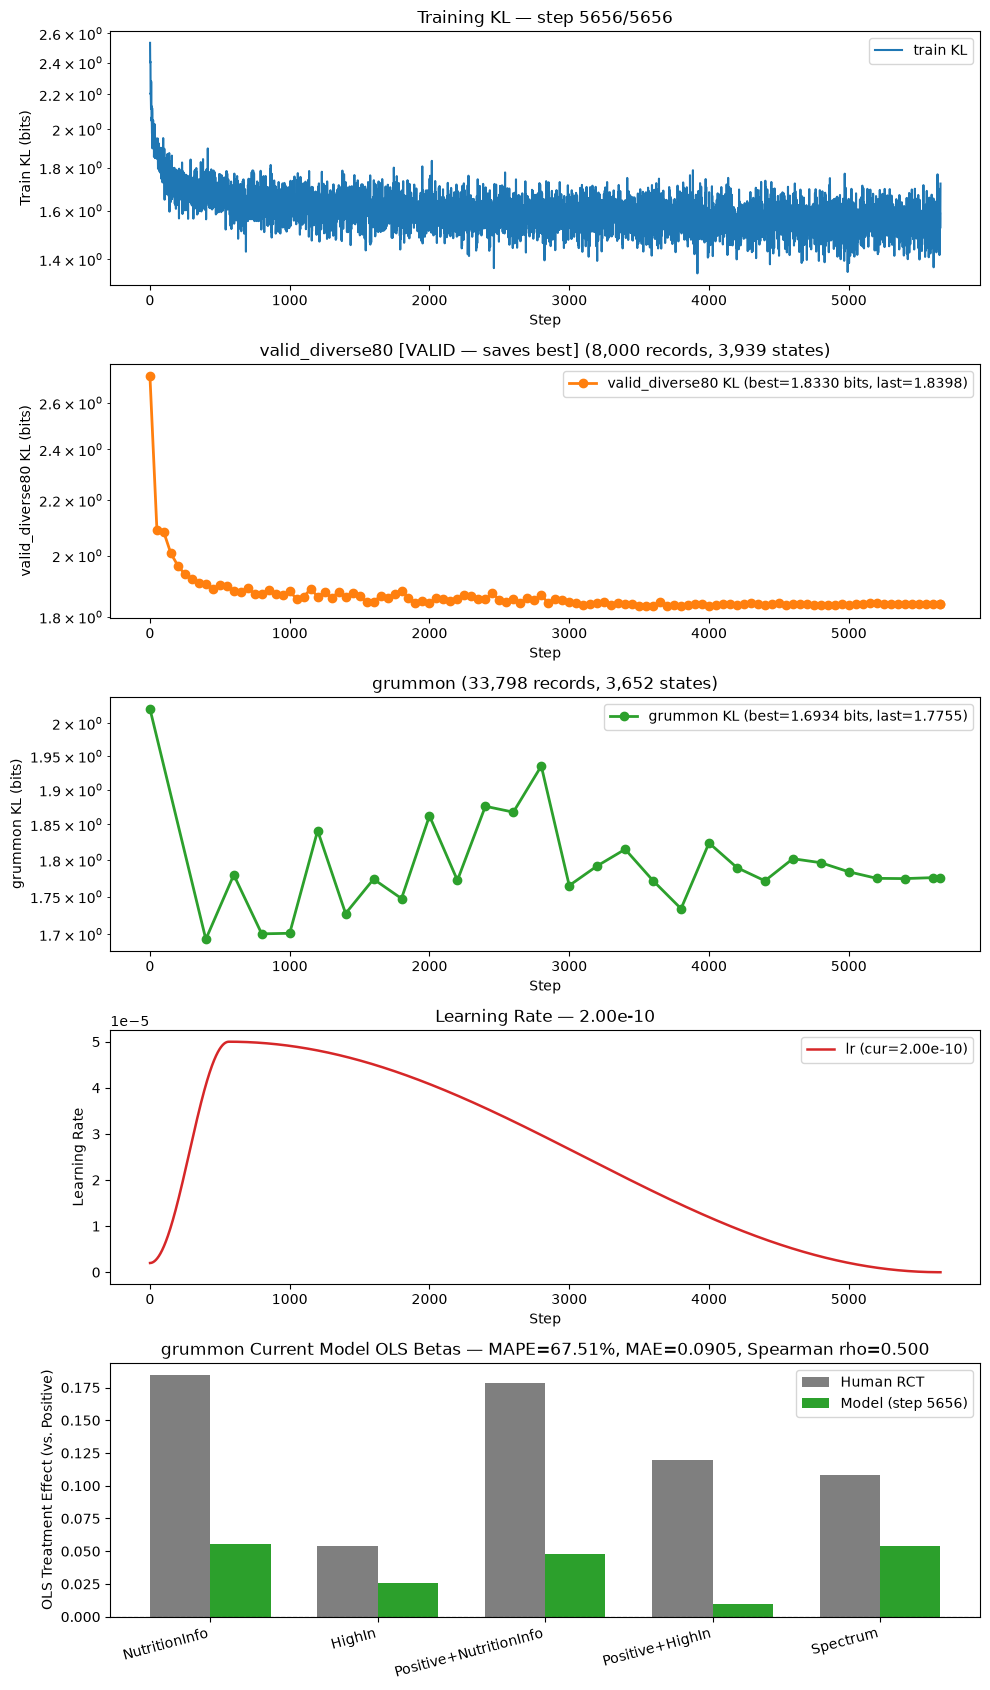

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.7238,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,1.8800,2.0907,—,—,—,—,—
2,1,100,1.8471,2.0809,—,—,—,—,—
3,1,150,1.7109,2.0074,—,—,—,—,—
4,1,200,1.6412,1.9656,—,—,—,—,—
5,1,250,1.6012,1.9369,—,—,—,—,—
6,1,300,1.6632,1.9226,—,—,—,—,—
7,1,350,1.7121,1.9087,—,—,—,—,—
8,1,400,1.6458,1.9033,1.6934,54.34,0.0701,0.0059,0.3000
9,1,450,1.6670,1.8878,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0553,0.1291
HighIn,0.0541,0.0259,0.0282
Positive+NutritionInfo,0.1788,0.0477,0.1312
Positive+HighIn,0.1194,0.0095,0.1099
Spectrum,0.1083,0.0542,0.0541


Resumed kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid at epoch 1, step 2150/5656 (best_valid_diverse80_kl=1.8437)


[W1109 18:06:58.050976197 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 113246208 bytes (free: 124583936, total: 33710276608).
[W1109 18:10:04.278141814 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 56623104 bytes (free: 126877696, total: 33710276608).
[W1109 18:12:43.663459711 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 56623104 bytes (free: 153419776, total: 33710276608).
[W1109 18:15:00.789565953 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 56623104 bytes (free: 99549184, total: 33710276608).
[W1109 18:17:36.393187263 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 33554432 bytes (free: 97452032, total: 33710276608).
[W1109 18:23:19.684759708 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM 

In [11]:
plotter = trainer.train()

## Train one-epoch 2

In [17]:
resume = False
val_every = [50, 500]
save_every = 50
epochs = 1
lr = 5e-6
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"
seed = 1
warmup_steps = 2000

if PRESET == "9b":
    trainer_cfg = dict(
        init_from="runs/kev-9b-resp-issp+twin2k-grouped-diversevalid-iid/best",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-diversevalid-iid-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        batch_size=26,
        grad_accum_steps=12,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        init_from="runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid/best",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        batch_size=12,
        grad_accum_steps=26,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = IIDTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    sort_within_step=True,
    warmup_steps=warmup_steps,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    seed=seed,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,iid
run_name,kev-0.8b-resp-issp+twin2k-grouped-diversevalid...
save_dir,runs/kev-0.8b-resp-issp+twin2k-grouped-diverse...
init_from,runs/kev-0.8b-resp-issp+twin2k-grouped-diverse...
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,1
epochs,1


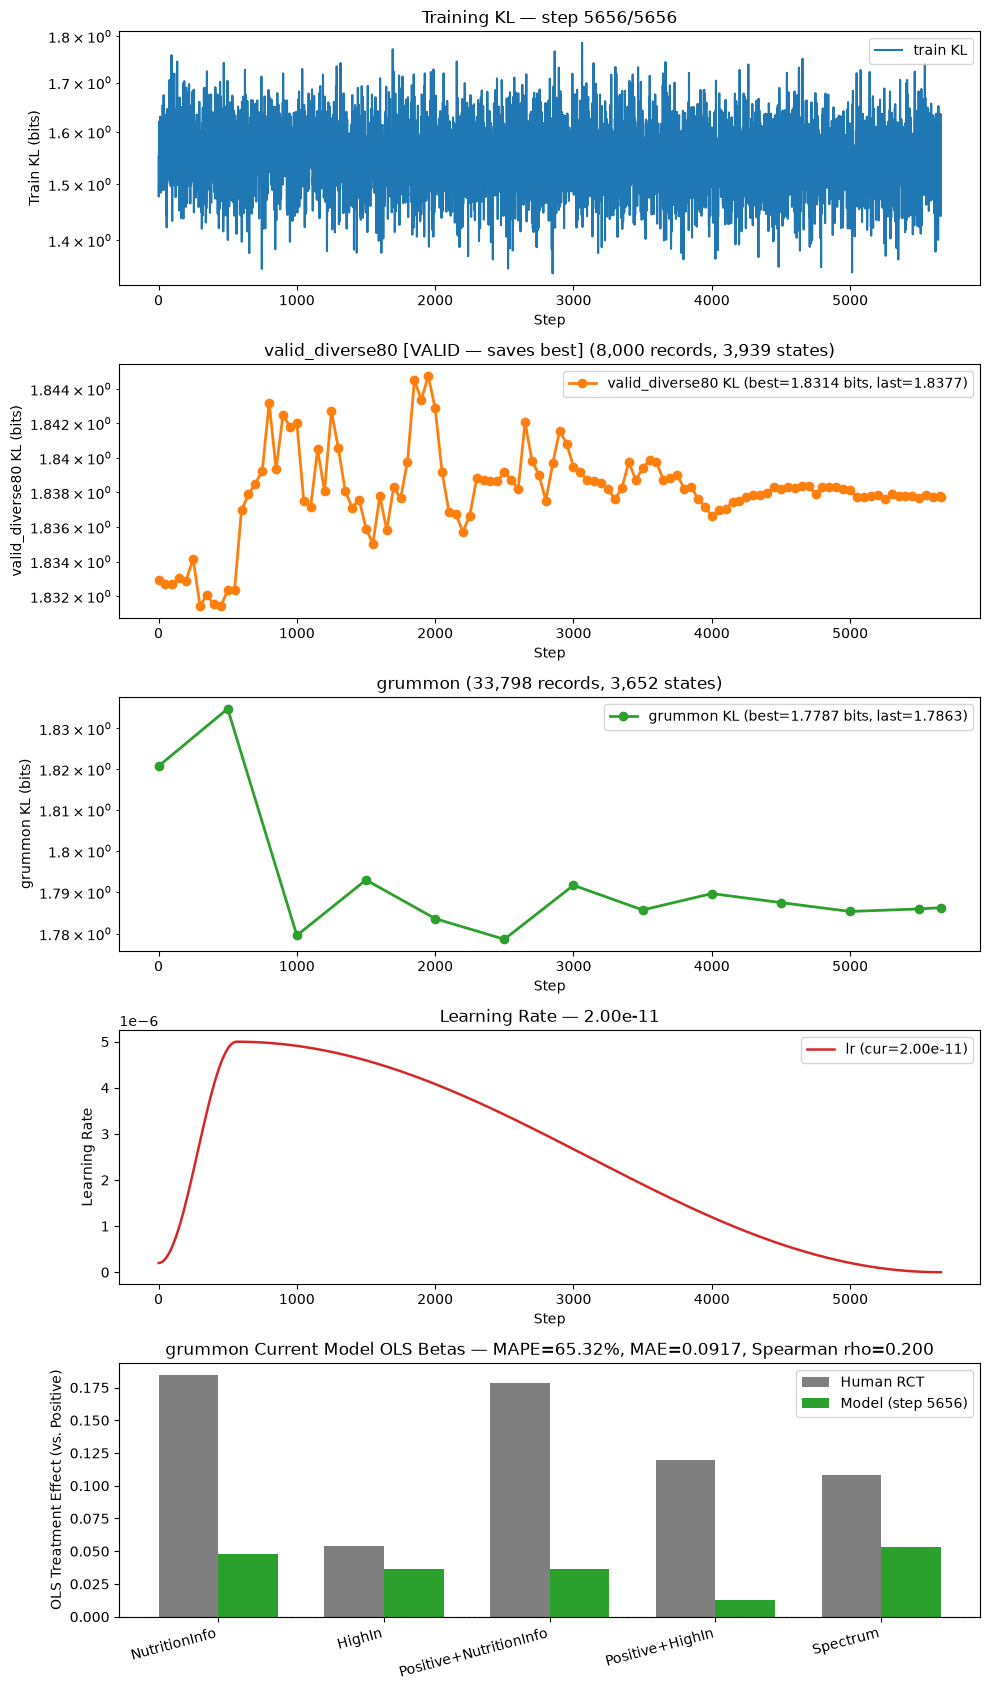

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,1.8330,1.8207,71.23,0.0926,0.0102,0.2000
1,1,50,1.6003,1.8327,—,—,—,—,—
2,1,100,1.5340,1.8327,—,—,—,—,—
3,1,150,1.4521,1.8330,—,—,—,—,—
4,1,200,1.5745,1.8329,—,—,—,—,—
5,1,250,1.5825,1.8342,—,—,—,—,—
6,1,300,1.4906,1.8314,—,—,—,—,—
7,1,350,1.7236,1.8321,—,—,—,—,—
8,1,400,1.5607,1.8315,—,—,—,—,—
9,1,450,1.5244,1.8314,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0475,0.1369
HighIn,0.0541,0.0363,0.0178
Positive+NutritionInfo,0.1788,0.0366,0.1423
Positive+HighIn,0.1194,0.0130,0.1065
Spectrum,0.1083,0.0533,0.0550


[W1109 22:56:03.935440529 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 65011712 bytes (free: 163774464, total: 33710276608).
[W1109 23:01:00.226018492 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 65011712 bytes (free: 129105920, total: 33710276608).
[W1109 23:03:27.507640773 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 65011712 bytes (free: 145358848, total: 33710276608).
[W1109 23:06:15.145365398 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 111149056 bytes (free: 212467712, total: 33710276608).
[W1109 23:16:49.974553570 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 111149056 bytes (free: 153747456, total: 33710276608).
[W1109 23:24:24.220520621 CUDACachingAllocator.cpp:3933] memory allocation failed with O

In [18]:
plotter = trainer.train()

## Train 2 epochs

In [19]:
resume = False
val_every = [50, 200]
save_every = 50
epochs = 2
lr = 5e-5
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-diversevalid-iid-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        batch_size=26,
        grad_accum_steps=12,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        batch_size=12,
        grad_accum_steps=26,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = IIDTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    sort_within_step=True,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,iid
run_name,kev-0.8b-resp-issp+twin2k-grouped-diversevalid...
save_dir,runs/kev-0.8b-resp-issp+twin2k-grouped-diverse...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,2


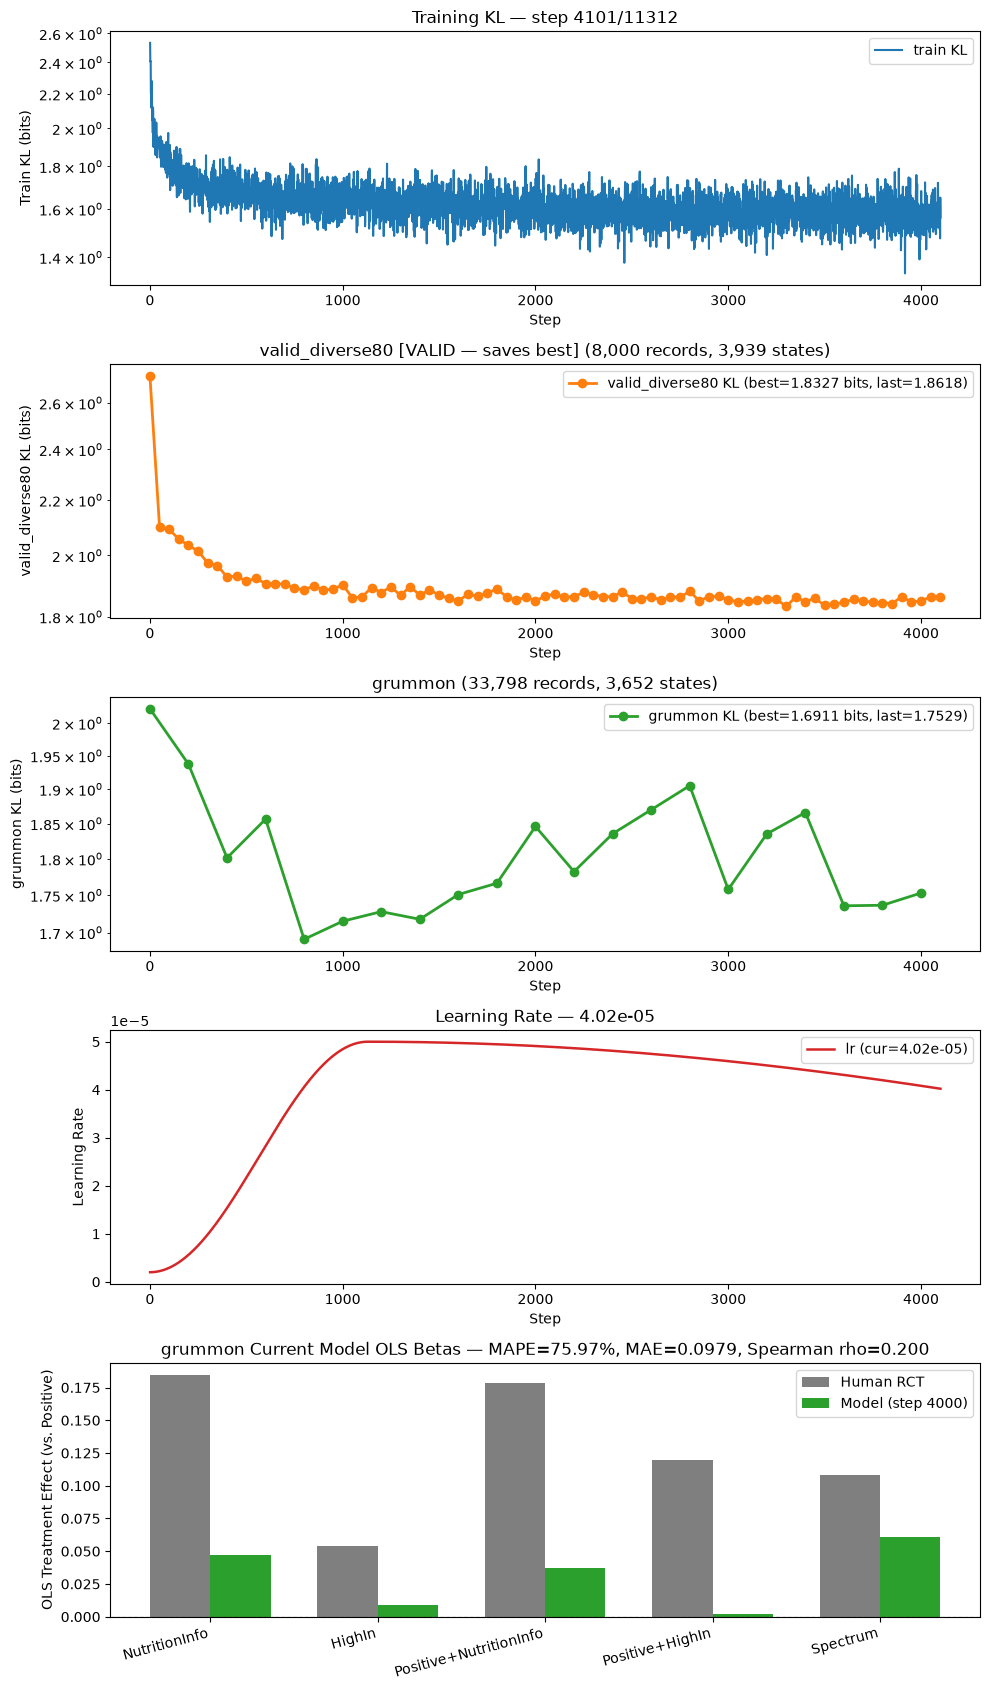

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.7238,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,1.8829,2.1000,—,—,—,—,—
2,1,100,1.8642,2.0916,—,—,—,—,—
3,1,150,1.7382,2.0571,—,—,—,—,—
4,1,200,1.6634,2.0350,1.9373,73.47,0.1044,0.0147,-0.9000
5,1,250,1.6844,2.0154,—,—,—,—,—
6,1,300,1.6776,1.9742,—,—,—,—,—
7,1,350,1.7282,1.9653,—,—,—,—,—
8,1,400,1.6649,1.9275,1.8014,65.95,0.0822,0.0079,-0.7000
9,1,450,1.6607,1.9307,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0472,0.1372
HighIn,0.0541,0.0086,0.0455
Positive+NutritionInfo,0.1788,0.0369,0.1419
Positive+HighIn,0.1194,0.0023,0.1171
Spectrum,0.1083,0.0607,0.0476


[W1110 03:45:41.644563157 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 65011712 bytes (free: 170131456, total: 33710276608).
[W1110 03:53:16.295378292 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 96468992 bytes (free: 136577024, total: 33710276608).
[W1110 03:59:06.892387411 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 94371840 bytes (free: 130285568, total: 33710276608).
[W1110 04:07:11.254652772 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 65011712 bytes (free: 180617216, total: 33710276608).
[W1110 04:09:27.616299217 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 111149056 bytes (free: 201588736, total: 33710276608).
[W1110 04:21:19.476251411 CUDACachingAllocator.cpp:3933] memory allocation failed with OO

KeyboardInterrupt: 

In [20]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [8]:
df_probe = trainer.probe_vram([
    (32, 16_000),
    (32, 20_000),
    (32, 24_000),
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
mq= 32, mc= 16000 -> OK  | peak_alloc=20.92 GiB (reserved=21.64 GiB) | worst=(26, 110, 131) (3,516 toks) | 1ep_steps=6,693
mq= 32, mc= 20000 -> OK  | peak_alloc=25.52 GiB (reserved=25.94 GiB) | worst=(20, 105, 221) (4,525 toks) | 1ep_steps=6,094
mq= 32, mc= 24000 -> OOM | peak_alloc=27.97 GiB (reserved=28.04 GiB) | worst=(32, 102, 158) (5,158 toks) | 1ep_steps=5,771


,max_questions,max_chars,groups_per_epoch,mean_q_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,32,16000,80307,23.43,6693,6693,"(26, 110, 131)",3516,20.92,21.64,OK
1,32,20000,73125,25.74,6094,6094,"(20, 105, 221)",4525,25.52,25.94,OK
2,32,24000,69249,27.18,5771,5771,"(32, 102, 158)",5158,27.97,28.04,OOM


## Show train records for epoch 1 based on seed 

In [4]:
import random
from collections import Counter
import data.base as _base_mod
importlib.reload(_base_mod)
from data.base import (
    _record_chars,
    group_train_records,
    group_train_records_mixed,
    group_train_records_iid,
)

DISPLAY_COLS = [
    "step", "mb_idx", "survey", "n_surveys", "n_personas",
    "n_questions", "n_families", "top_family", "top_family_share", "persona", "qids",
]


def _q_family(qid):
    yr, v = qid.split(":")
    if yr != "twin2k":
        return qid
    return f"twin2k:{v.split('_')[0]}"


def epoch1_question_order(seed, *, group_fn=group_train_records_mixed, batch_size=1, grad_accum_steps=12):
    epoch_rng = random.Random(f"{seed}:epoch:0")
    groups = group_fn(
        train_records,
        max_questions=trainer_cfg["max_questions_per_group"],
        max_chars=trainer_cfg["max_chars_per_group"],
        rng=epoch_rng,
    )
    rows = []
    for mb_idx, start in enumerate(range(0, len(groups), batch_size)):
        mb_groups = groups[start : start + batch_size]
        recs = [r for g in mb_groups for r in g]
        qids = [r["qid"] for r in recs]
        surveys = sorted({q.split(":")[0] for q in qids})
        personas = list(dict.fromkeys(r["persona"] for r in recs))
        fam_counts = Counter(_q_family(q) for q in qids)
        top_fam, top_cnt = fam_counts.most_common(1)[0]
        if len(mb_groups) == 1:
            padded_chars = len(recs[0]["persona"]) + 80 + len(recs) * max(_record_chars(r) for r in recs)
        else:
            padded_chars = len(recs) * max(len(r["persona"]) + 80 + _record_chars(r) for r in recs)
        rows.append(
            {
                "step": (mb_idx // grad_accum_steps) + 1,
                "mb_idx": mb_idx,
                "survey": surveys[0] if len(surveys) == 1 else f"mixed({len(surveys)}): {','.join(surveys[:3])}..",
                "n_surveys": len(surveys),
                "n_personas": len(personas),
                "n_questions": len(qids),
                "n_families": len(fam_counts),
                "top_family": f"{top_fam} ({top_cnt}/{len(qids)})",
                "top_family_share": round(top_cnt / len(qids), 3),
                "persona": personas[0] if len(personas) == 1 else f"[{len(personas)} distinct] {personas[0][:32]}...",
                "qids": qids,
                "_personas_set": set(personas),
                "_surveys_set": set(surveys),
                "_padded_chars": padded_chars,
            }
        )
    return pd.DataFrame(rows), groups


def summarize_chunking(df_order, label):
    qid_tuples = Counter(tuple(q) for q in df_order["qids"])
    dup_mbs = sum(v for v in qid_tuples.values() if v > 1)
    step_df = df_order.groupby("step").agg(
        n_questions=("n_questions", "sum"),
        n_personas=("_personas_set", lambda s: len(set().union(*s))),
        n_surveys=("_surveys_set", lambda s: len(set().union(*s))),
        n_unique_qids=("qids", lambda s: len({q for qs in s for q in qs})),
        n_unique_families=("qids", lambda s: len({_q_family(q) for qs in s for q in qs})),
    )
    return {
        "strategy": label,
        "microbatches": len(df_order),
        "steps": int(df_order["step"].max()),
        "mean_q/mb": round(df_order["n_questions"].mean(), 2),
        "tiny_mbs(<=5)": int((df_order["n_questions"] <= 5).sum()),
        "identical_qid_mbs": f"{dup_mbs:,} ({dup_mbs / len(df_order):.2%})",
        "personas/mb": round(df_order["n_personas"].mean(), 1),
        "personas/step": round(step_df["n_personas"].mean(), 1),
        "surveys/step": round(step_df["n_surveys"].mean(), 2),
        "unique_fams/step": round(step_df["n_unique_families"].mean(), 1),
        "padded_Mchars/ep": round(df_order["_padded_chars"].sum() / 1e6, 1),
    }

In [6]:
SEED_TO_CHECK = 0
df_old = epoch1_question_order(SEED_TO_CHECK, group_fn=group_train_records, batch_size=1, grad_accum_steps=12)
df_order = epoch1_question_order(SEED_TO_CHECK, group_fn=group_train_records_mixed, batch_size=1, grad_accum_steps=12)
df_iid = epoch1_question_order(SEED_TO_CHECK, group_fn=group_train_records_iid, batch_size=26, grad_accum_steps=12)

display(pd.DataFrame([
    summarize_chunking(df_old, "group_train_records (old, bs=1, ga=12)"),
    summarize_chunking(df_order, "group_train_records_mixed (new, bs=1, ga=12)"),
    summarize_chunking(df_iid, "group_train_records_iid (iid, bs=26, ga=12)"),
]))
print("=== 1. OLD group_train_records (first 12 microbatches = Step 1) ===")
display(df_old[DISPLAY_COLS].head(12))
print("=== 2. NEW group_train_records_mixed (first 12 microbatches = Step 1) ===")
display(df_order[DISPLAY_COLS].head(12))
print("=== 3. UNGROUPED group_train_records_iid (first 12 microbatches = Step 1, 26 i.i.d. records/mb) ===")
display(df_iid[DISPLAY_COLS].head(12))

In [7]:
SEED_TO_CHECK = 1
df_iid_s1 = epoch1_question_order(SEED_TO_CHECK, group_fn=group_train_records_iid, batch_size=26, grad_accum_steps=12)
df_steps = df_iid_s1.groupby("step").agg(
    n_microbatches=("mb_idx", "count"),
    total_questions=("n_questions", "sum"),
    n_personas=("_personas_set", lambda s: len(set().union(*s))),
    n_surveys=("_surveys_set", lambda s: len(set().union(*s))),
    n_unique_qids=("qids", lambda s: len({q for qs in s for q in qs})),
    n_unique_families=("qids", lambda s: len({_q_family(q) for qs in s for q in qs})),
).reset_index()
print(
    f"seed={SEED_TO_CHECK} (IID) | microbatches={len(df_iid_s1):,} | "
    f"steps={df_iid_s1['step'].max():,} | questions={df_iid_s1['n_questions'].sum():,}"
)
display(df_steps.head(15))
display(df_iid_s1[DISPLAY_COLS])

,strategy,microbatches,steps,mean_q/mb,tiny_mbs(<=5),identical_qid_mbs,personas/mb,personas/step,surveys/step,unique_fams/step,padded_Mchars/ep
0,"group_train_records (old, bs=1, ga=12)",73125,6094,25.74,6000,"31,127 (42.57%)",1.0,12.0,5.11,151.4,1060.0
1,"group_train_records_mixed (new, bs=1, ga=12)",73125,6094,25.74,17,"2,054 (2.81%)",1.0,12.0,5.12,161.6,1262.4
2,"group_train_records_iid (iid, bs=26, ga=12)",72383,6032,26.00,0,0 (0.00%),25.9,303.3,11.00,166.1,1934.3


=== 1. OLD group_train_records (first 12 microbatches = Step 1) ===


,step,mb_idx,survey,n_surveys,n_personas,n_questions,n_families,top_family,top_family_share,persona,qids
0,1,0,2019,1,1,32,32,2019:v50 (1/32),0.031,"Sex=Male, Age=30-49, Education=High school or ...","[2019:v50, 2019:v29, 2019:v54, 2019:v21, 2019:..."
1,1,1,twin2k,1,1,32,9,twin2k:QID232 (14/32),0.438,"Sex=Male, Age=65+, Education=Associate's degre...","[twin2k:QID232_8, twin2k:QID232_19, twin2k:QID..."
2,1,2,twin2k,1,1,32,16,twin2k:QID125 (16/32),0.500,"Sex=Male, Age=30-49, Education=High school or ...","[twin2k:QID125_8, twin2k:QID70, twin2k:QID272,..."
3,1,3,twin2k,1,1,32,7,twin2k:QID247 (10/32),0.312,"Sex=Female, Age=30-49, Education=College gradu...","[twin2k:QID25_5, twin2k:QID25_7, twin2k:QID28_..."
4,1,4,twin2k,1,1,32,5,twin2k:QID25 (18/32),0.562,"Sex=Female, Age=18-29, Education=High school o...","[twin2k:QID25_22, twin2k:QID25_36, twin2k:QID2..."
5,1,5,twin2k,1,1,32,4,twin2k:QID25 (18/32),0.562,"Sex=Male, Age=30-49, Education=High school or ...","[twin2k:QID25_14, twin2k:QID233_1, twin2k:QID2..."
6,1,6,2019,1,1,32,32,2019:v50 (1/32),0.031,"Sex=Female, Age=30-49, Education=College gradu...","[2019:v50, 2019:v29, 2019:v54, 2019:v21, 2019:..."
7,1,7,twin2k,1,1,25,3,twin2k:QID278 (14/25),0.560,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID276_12, twin2k:QID276_6, twin2k:QID..."
8,1,8,twin2k,1,1,32,28,twin2k:QID125 (5/32),0.156,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID148, twin2k:QID169, twin2k:QID275, ..."
9,1,9,2015,1,1,26,26,2015:v35 (1/26),0.038,"Sex=Male, Age=65+, Education=High school or so...","[2015:v35, 2015:v32, 2015:v9, 2015:v29, 2015:v..."


=== 2. NEW group_train_records_mixed (first 12 microbatches = Step 1) ===


,step,mb_idx,survey,n_surveys,n_personas,n_questions,n_families,top_family,top_family_share,persona,qids
0,1,0,2019,1,1,20,20,2019:v49 (1/20),0.050,"Sex=Male, Age=30-49, Education=High school or ...","[2019:v49, 2019:v48, 2019:v32, 2019:v1, 2019:v..."
1,1,1,twin2k,1,1,25,3,twin2k:QID278 (12/25),0.480,"Sex=Male, Age=65+, Education=Associate's degre...","[twin2k:QID278_14, twin2k:QID278_5, twin2k:QID..."
2,1,2,twin2k,1,1,18,2,twin2k:QID29 (17/18),0.944,"Sex=Male, Age=30-49, Education=High school or ...","[twin2k:QID34, twin2k:QID29_4, twin2k:QID29_24..."
3,1,3,twin2k,1,1,32,23,twin2k:QID26 (3/32),0.094,"Sex=Female, Age=30-49, Education=College gradu...","[twin2k:QID26_7, twin2k:QID84_6, twin2k:QID232..."
4,1,4,twin2k,1,1,32,16,twin2k:QID25 (5/32),0.156,"Sex=Female, Age=18-29, Education=High school o...","[twin2k:QID287_12, twin2k:QID247_4, twin2k:QID..."
5,1,5,twin2k,1,1,30,16,twin2k:QID250 (6/30),0.200,"Sex=Male, Age=30-49, Education=High school or ...","[twin2k:QID250_1, twin2k:QID251_2, twin2k:QID2..."
6,1,6,2019,1,1,20,20,2019:v48 (1/20),0.050,"Sex=Female, Age=30-49, Education=College gradu...","[2019:v48, 2019:v49, 2019:v32, 2019:v9, 2019:v..."
7,1,7,twin2k,1,1,32,17,twin2k:QID25 (6/32),0.188,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID203_6, twin2k:QID25_38, twin2k:QID2..."
8,1,8,twin2k,1,1,8,8,twin2k:QID57 (1/8),0.125,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID57, twin2k:QID59, twin2k:QID58, twi..."
9,1,9,2015,1,1,26,26,2015:v12 (1/26),0.038,"Sex=Male, Age=65+, Education=High school or so...","[2015:v12, 2015:v34, 2015:v23, 2015:v18, 2015:..."


=== 3. UNGROUPED group_train_records_iid (first 12 microbatches = Step 1, 26 i.i.d. records/mb) ===


,step,mb_idx,survey,n_surveys,n_personas,n_questions,n_families,top_family,top_family_share,persona,qids
0,1,0,"mixed(8): 2015,2016,2018..",8,24,26,20,twin2k:QID125 (5/26),0.192,"[24 distinct] Sex=Male, Age=18-29, Education=H...","[2024:v23, 2024:v23, 2020:v52, 2015:v40, 2020:..."
1,1,1,"mixed(7): 2015,2016,2018..",7,26,26,22,twin2k:QID125 (5/26),0.192,"[26 distinct] Sex=Male, Age=65+, Education=Col...","[twin2k:QID125_21, 2018:v63, twin2k:QID220, tw..."
2,1,2,"mixed(10): 2015,2016,2018..",10,26,26,23,twin2k:QID203 (3/26),0.115,"[26 distinct] Sex=Female, Age=30-49, Education...","[2015:V16, 2015:v23, 2021:v37, 2015:v19, 2021:..."
3,1,3,"mixed(9): 2016,2018,2019..",9,26,26,22,twin2k:QID232 (3/26),0.115,"[26 distinct] Sex=Female, Age=50-64, Education...","[2018:v13, 2021:v39, 2016:v49, twin2k:QID232_1..."
4,1,4,"mixed(9): 2015,2016,2018..",9,26,26,19,twin2k:QID232 (3/26),0.115,"[26 distinct] Sex=Male, Age=18-29, Education=C...","[2020:v58, 2023:v9, twin2k:QID289_1, 2020:v58,..."
5,1,5,"mixed(6): 2015,2019,2022..",6,26,26,17,twin2k:QID237 (4/26),0.154,"[26 distinct] Sex=Female, Age=30-49, Education...","[twin2k:QID237_5, 2015:v64, 2023:v47, twin2k:Q..."
6,1,6,"mixed(7): 2015,2017,2019..",7,26,26,19,twin2k:QID9 (5/26),0.192,"[26 distinct] Sex=Female, Age=65+, Education=H...","[2024:v44, 2024:v55, twin2k:QID9_046, twin2k:Q..."
7,1,7,"mixed(4): 2017,2023,2024..",4,26,26,13,twin2k:QID25 (6/26),0.231,"[26 distinct] Sex=Male, Age=30-49, Education=C...","[2023:v42, 2023:v58, twin2k:QID25_22, 2017:v34..."
8,1,8,"mixed(8): 2017,2018,2019..",8,26,26,19,twin2k:QID244 (3/26),0.115,"[26 distinct] Sex=Female, Age=30-49, Education...","[2024:v65, twin2k:QID84_8, twin2k:QID233_4, tw..."
9,1,9,"mixed(7): 2018,2019,2020..",7,26,26,20,twin2k:QID234 (3/26),0.115,"[26 distinct] Sex=Female, Age=65+, Education=H...","[2023:v24, 2023:v35, twin2k:QID235_6, twin2k:Q..."


In [14]:
len(groups_old), len(groups_old[0])

(73125, 32)

In [15]:
len(groups_iid), len(groups_iid[0])

(1881950, 1)

In [13]:
groups_iid[0]

[{'qid': '2024:v23',
  'year': '2024',
  'v': 'v23',
  'type': 'score',
  'question': 'How would you rate your ability to do the following? Using the Internet',
  'option_texts': ['Very good',
   'Good',
   'Neither good nor bad',
   'Bad',
   'Very bad'],
  'personas': {'SEX': 'Male',
   'AGE': '18-29',
   'EDULEVEL': 'High school or some college',
   'RELIGGRP': 'Atheist',
   'ATTEND': 'Never',
   'URBRURAL': 'A big city',
   'MARITAL': 'Never been married',
   'MAINSTAT': 'In paid work',
   'UNION': 'No',
   'US_REG': 'Northeast',
   'US_ETHN1': 'Japan'},
  'attribute': 'SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+URBRURAL+MARITAL+MAINSTAT+UNION+US_REG+US_ETHN1',
  'persona': 'Sex=Male, Age=18-29, Education=High school or some college, Religion=Atheist, Attendance of religious services=Never, Place of living=A big city, Marital status=Never been married, Main activity=In paid work, Trade union membership=No, Region=Northeast, Ancestry=Japan',
  'n': 1,
  'human_dist': array([1., 0., 0., 0., 0.

In [ ]:
SEED_TO_CHECK = 1
df_iid_s1 = epoch1_question_order(SEED_TO_CHECK, group_fn=group_train_records_iid, batch_size=26, grad_accum_steps=12)
df_steps = df_iid_s1.groupby("step").agg(
    n_microbatches=("mb_idx", "count"),
    total_questions=("n_questions", "sum"),
    n_personas=("_personas_set", lambda s: len(set().union(*s))),
    n_surveys=("_surveys_set", lambda s: len(set().union(*s))),
    n_unique_qids=("qids", lambda s: len({q for qs in s for q in qs})),
    n_unique_families=("qids", lambda s: len({_q_family(q) for qs in s for q in qs})),
).reset_index()
print(
    f"seed={SEED_TO_CHECK} (IID) | microbatches={len(df_iid_s1):,} | "
    f"steps={df_iid_s1['step'].max():,} | questions={df_iid_s1['n_questions'].sum():,}"
)
display(df_steps.head(15))
display(df_iid_s1[DISPLAY_COLS])

seed=1 (IID) | microbatches=72,383 | steps=6,032 | questions=1,881,950


,step,n_microbatches,total_questions,n_personas,n_surveys,n_unique_qids,n_unique_families
0,1,12,312,301,11,279,170
1,2,12,312,301,11,268,159
2,3,12,312,301,11,272,155
3,4,12,312,298,11,267,157
4,5,12,312,307,11,275,176
5,6,12,312,300,11,278,165
6,7,12,312,304,11,275,166
7,8,12,312,302,11,276,165
8,9,12,312,299,11,276,164
9,10,12,312,306,11,267,170


,step,mb_idx,survey,n_surveys,n_personas,n_questions,n_families,top_family,top_family_share,persona,qids
0,1,0,"mixed(5): 2018,2020,2021..",5,26,26,18,twin2k:QID125 (5/26),0.192,"[26 distinct] Sex=Female, Age=18-29, Education...","[2021:v51, 2020:v56, 2018:v46, 2018:v64, 2020:..."
1,1,1,"mixed(8): 2015,2016,2018..",8,26,26,23,twin2k:QID125 (3/26),0.115,"[26 distinct] Sex=Female, Age=30-49, Education...","[2020:v46, 2020:v34, 2020:v53, twin2k:QID69, 2..."
2,1,2,"mixed(9): 2015,2016,2017..",9,26,26,21,twin2k:QID232 (3/26),0.115,"[26 distinct] Sex=Female, Age=50-64, Education...","[twin2k:QID27_7, 2024:v53, 2015:v74, 2023:v49,..."
3,1,3,"mixed(9): 2015,2016,2017..",9,26,26,18,twin2k:QID232 (6/26),0.231,"[26 distinct] Sex=Female, Age=50-64, Education...","[twin2k:QID232_18, twin2k:QID232_20, twin2k:QI..."
4,1,4,"mixed(10): 2015,2017,2018..",10,26,26,20,twin2k:QID9 (4/26),0.154,"[26 distinct] Sex=Male, Age=18-29, Education=C...","[twin2k:QID287_5, twin2k:QID289_3, twin2k:QID2..."
...,...,...,...,...,...,...,...,...,...,...,...
72378,6032,72378,"mixed(6): 2018,2019,2020..",6,26,26,16,twin2k:QID25 (6/26),0.231,"[26 distinct] Sex=Female, Age=30-49, Education...","[twin2k:QID233_2, 2019:v51, twin2k:QID233_11, ..."
72379,6032,72379,"mixed(7): 2015,2017,2019..",7,26,26,17,twin2k:QID245 (4/26),0.154,"[26 distinct] Sex=Female, Age=30-49, Education...","[2022:v1, 2015:v13, twin2k:QID28_6, twin2k:QID..."
72380,6032,72380,"mixed(5): 2017,2019,2023..",5,26,26,16,twin2k:QID236 (5/26),0.192,"[26 distinct] Sex=Male, Age=65+, Education=Hig...","[twin2k:QID236_6, twin2k:QID236_6, twin2k:QID2..."
72381,6032,72381,"mixed(5): 2017,2019,2022..",5,26,26,14,twin2k:QID279 (4/26),0.154,"[26 distinct] Sex=Male, Age=50-64, Education=C...","[twin2k:QID251_4, twin2k:QID250_4, 2024:v67, t..."
